In [1]:
from google.colab import files
uploaded = files.upload()

Saving student_performance_dataset.csv to student_performance_dataset.csv


In [2]:
import pandas as pd

df = pd.read_csv("student_performance_dataset.csv")
print(df.shape)
display(df.head())

(1000, 12)


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


Random Forest Accuracy: 98.0 %


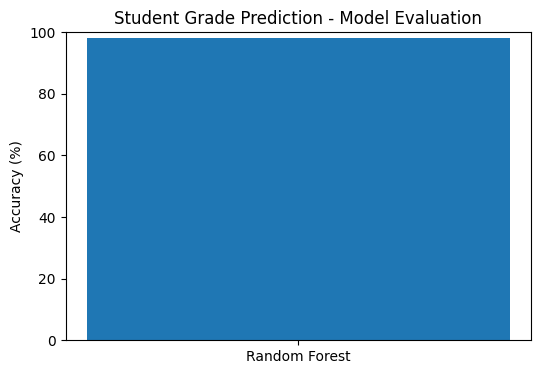

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Separate input and output
X = df.drop(columns=["final_grade", "student_id"], errors="ignore")
y = df["final_grade"]

# Convert categorical columns
X = pd.get_dummies(X)

# Fill missing values
X = X.fillna(X.median(numeric_only=True))
X = X.fillna(0)

# Encode target if it contains A, B, C, D, F
if y.dtype == "object":
    y = y.map({"F": 0, "D": 1, "C": 2, "B": 3, "A": 4})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred) * 100

print("Random Forest Accuracy:", round(accuracy, 2), "%")

# Plot graph
plt.figure(figsize=(6, 4))
plt.bar(["Random Forest"], [accuracy])
plt.ylabel("Accuracy (%)")
plt.title("Student Grade Prediction - Model Evaluation")
plt.ylim(0, 100)
plt.show()

In [4]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.89      0.94      0.92        18
           2       0.96      1.00      0.98        52
           3       1.00      0.99      0.99        71
           4       1.00      1.00      1.00        57

    accuracy                           0.98       200
   macro avg       0.77      0.79      0.78       200
weighted avg       0.97      0.98      0.98       200



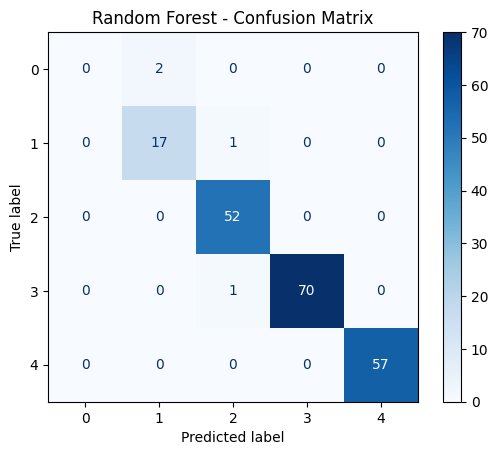

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm)

display.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

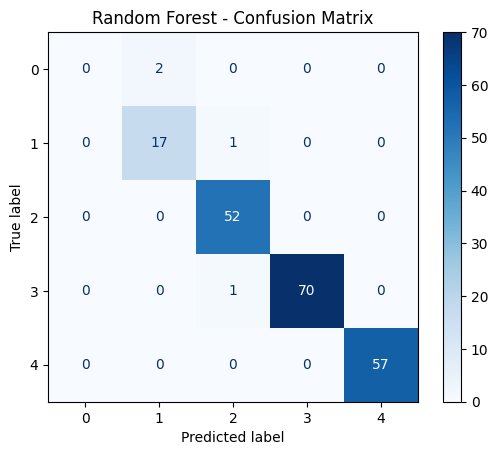

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [7]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report")
print(classification_report(y_test, y_pred, zero_division=0))

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.89      0.94      0.92        18
           2       0.96      1.00      0.98        52
           3       1.00      0.99      0.99        71
           4       1.00      1.00      1.00        57

    accuracy                           0.98       200
   macro avg       0.77      0.79      0.78       200
weighted avg       0.97      0.98      0.98       200



In [8]:
import joblib

joblib.dump(model, "student_grade_model.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")

print("Model saved successfully!")

Model saved successfully!


In [9]:
from google.colab import files

files.download("student_grade_model.pkl")
files.download("feature_names.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
# Take one student record from the test dataset
sample = X_test.iloc[[0]]

# Predict the grade
prediction = model.predict(sample)[0]

# Convert predicted number into grade
grade_mapping = {
    0: "F",
    1: "D",
    2: "C",
    3: "B",
    4: "A"
}

print("Predicted Student Grade:", grade_mapping.get(prediction, prediction))

Predicted Student Grade: C
